# import library and data sheeet

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import urllib.request

#1 . Load datasheet

In [4]:
file_name = "Mall_Customers.csv"
if not os.path.exists(file_name):
    print(f"{file_name} not found locally. Downloading...")
    url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
    urllib.request.urlretrieve(url, file_name)
    print("Download complete.")

df = pd.read_csv(file_name)

Mall_Customers.csv not found locally. Downloading...
Download complete.


##Basic exploration

In [5]:
print(df.head())
print(df.tail())
print("Shape:", df.shape)
df.info()
print(df.describe())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83
Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column     

##3 Missing value and duplicate

In [6]:
print("Missing Values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Missing Values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplicates: 0


##4 Gender count

In [7]:
gender_count = df['Gender'].value_counts()
print("\nGender Count:\n", gender_count)


Gender Count:
 Gender
Female    112
Male       88
Name: count, dtype: int64


##5 Numerical Statics using numpy

In [8]:
columns = [
    'Age',
    'Annual Income (k$)',
    'Spending Score (1-100)'
]

for col in columns:
    arr = df[col].to_numpy()
    print("\n", col)
    print("Mean:", np.mean(arr))
    print("Median:", np.median(arr))
    print("Minimum:", np.min(arr))
    print("Maximum:", np.max(arr))


 Age
Mean: 38.85
Median: 36.0
Minimum: 18
Maximum: 70

 Annual Income (k$)
Mean: 60.56
Median: 61.5
Minimum: 15
Maximum: 137

 Spending Score (1-100)
Mean: 50.2
Median: 50.0
Minimum: 1
Maximum: 99


##6 Age group analysis

In [9]:
bins = [17, 29, 39, 49, 59, 70]
labels = ['18-29', '30-39', '40-49', '50-59', '60-70']

df['Age Group'] = pd.cut(
    df['Age'], bins=bins, labels=labels
)

age_analysis = df.groupby(
    'Age Group', observed=False
)['Spending Score (1-100)'].mean()

print("\nAge Group Analysis:\n", age_analysis)
print("Highest Spending Group:", age_analysis.idxmax())


Age Group Analysis:
 Age Group
18-29    58.581818
30-39    61.098361
40-49    34.948718
50-59    34.720000
60-70    43.000000
Name: Spending Score (1-100), dtype: float64
Highest Spending Group: 30-39


##7 Gender comparision

In [10]:
print("\nGender Analysis:")
print(df.groupby('Gender')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean())


Gender Analysis:
        Annual Income (k$)  Spending Score (1-100)
Gender                                            
Female           59.250000               51.526786
Male             62.227273               48.511364


##8 Top 10 customer

In [11]:
top10 = df.sort_values(
    by='Spending Score (1-100)',
    ascending=False
).head(10)

print("\nTop 10 Customers:\n", top10)


Top 10 Customers:
      CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
11           12  Female   35                  19                      99   
19           20  Female   35                  23                      98   
145         146    Male   28                  77                      97   
185         186    Male   30                  99                      97   
167         168  Female   33                  86                      95   
127         128    Male   40                  71                      95   
7             8  Female   23                  18                      94   
163         164  Female   31                  81                      93   
141         142    Male   32                  75                      93   
173         174    Male   36                  87                      92   

    Age Group  
11      30-39  
19      30-39  
145     18-29  
185     30-39  
167     30-39  
127     40-49  
7       18-29  
163     30-39  

##Gender count bar chart

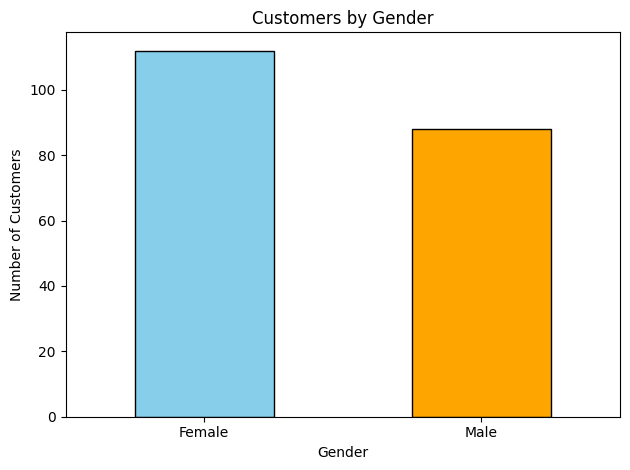

In [12]:
gender_count.plot(
    kind='bar',
    color=['skyblue', 'orange'],
    edgecolor='black'
)

plt.title('Customers by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##10 Annual income vs spending score

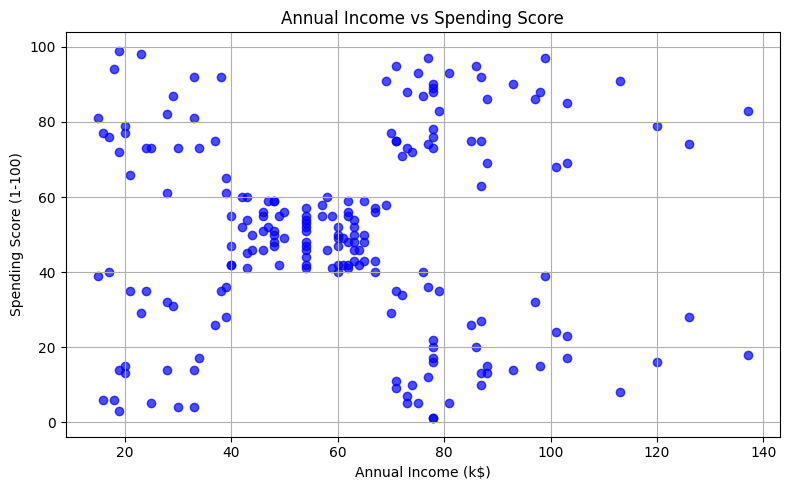

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    color='blue',
    alpha=0.7
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True)
plt.tight_layout()
plt.show()